In [ ]:
%load_ext autoreload
%autoreload 2

from src.DicomRTHandler import DicomRTHandler
from src.config_presets.tools.load_config import load_config
import numpy as np

config = load_config('HNC/UMCG_data.yaml')


ct_folder = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9296488\no_contrast\CT"
rtdose_file = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9296488\no_contrast\RTDOSE\IM1.DCM"
rtstruct_file = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9296488\no_contrast\RTSTRUCT\RS1.2.752.243.1.1.20220324125917617.1240.35401.dcm"
CITOR_RTSTRUCT_DIR = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9296488\no_contrast\RTSTRUCT"
DLC_RTSTRUCT_DIR = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\DLC\9296488\no_contrast\RTSTRUCT"  # can also be None if no DLCs are needed


# # # directories of the CT, rtdose and rtstruct dicom files
# # ct_folder = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9296488\no_contrast\CT"
# # rtdose_file = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9296488\no_contrast\RTDOSE\IM1.DCM"
# # CITOR_RTSTRUCT_DIR = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9296488\no_contrast\RTSTRUCT"

# # # folder of deep learning contours (if applicable)
# DLC_RTSTRUCT_DIR = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\DLC\9296488\no_contrast\RTSTRUCT"
# # #DLC_RTSTRUCT_DIR = None

# # # # # contrast
# ct_folder = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\0059896\with_contrast\CT"
# # no contrast
# #ct_folder = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\0059896\no_contrast\20180716\CT"
# rtdose_file = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\0059896\no_contrast\20180716\RTDOSE\RTDOSE_1.2.752.243.1.1.20180725161405473.2160.62180.dcm"
# CITOR_RTSTRUCT_DIR = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\0059896\no_contrast\20180716\RTSTRUCT"
# DLC_RTSTRUCT_DIR = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\DLC\0059896\no_contrast\RTSTRUCT"

# # # # # # # contrast
# ct_folder = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9980149\with_contrast\CT"
# # no contrast
# #ct_folder = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9980149\no_contrast\CT"
# rtdose_file = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9980149\no_contrast\RTDOSE\IM1.DCM"
# CITOR_RTSTRUCT_DIR = r"\\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9980149\no_contrast\RTSTRUCT"
# DLC_RTSTRUCT_DIR = None


# enable and disable verbose print statements (mostly used for debugging)
VERBOSE = True

handler = DicomRTHandler(config, verbose=VERBOSE)



The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
src\config_presets\HNC/UMCG_data.yaml


In [98]:
# Load data 

# # load the CT files
handler.load_ct_series(ct_folder)

# # load the RTDOSE file, and resample it to the CT grid
handler.load_rtdose(rtdose_file)

# load the available RTSTRUCT files (loops through a folder of DICOM files)
handler.load_rtstructs(CITOR_RTSTRUCT_DIR, DLC_folder_dir = DLC_RTSTRUCT_DIR, fix_uids=True)
# If no DLCs, then:
# handler.load_rtstructs(CITOR_RTSTRUCT_DIR, fix_uids=False)




# Print summary
#handler.print_summary()


Loading CT series from \\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9296488\no_contrast\CT...
Loading RTDOSE from \\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9296488\no_contrast\RTDOSE\IM1.DCM...
Loading RTSTRUCT from \\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9296488\no_contrast\RTSTRUCT...
Loading RTSTRUCT from \\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9296488\no_contrast\RTSTRUCT...
  Checking file: \\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\Now_Has_endpoint_for_at_least_1_toxicity\9296488\no_contrast\RTSTRUCT\IM1.DCM...
Removed ROIs: ['PTV_6600', 'CTV_6600', 'Verif_Mask', 'IsocCT', 'IsocA1F']
Kept ROIs: []
Fixing RTSTRUCT references to match CT series...
Fixed 0 contour references, 0 failed
  Checking file: \\zkh\appdata\RTDicom\Projectline_HNC_modelling\PRI2MA\No

In [99]:
len(handler.structure_masks_dict)

29

In [100]:
# prints some (very basic) metadata about the loaded data
handler.print_summary()


DICOM RT DATA SUMMARY

CT Series:
  PatientID: 9296488
  ScanDate: 20201118
  Manufacturer: SIEMENS
  ModelName: SOMATOM Definition AS
  KiloVoltPeak: 100.0
  ImageOrientationPatient: [1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0, 0, 1]
  ImagePositionPatient: [-249.51171875, -473.01171875, -190.0]
  Spacing: [0.9765625, 0.9765625]
  RescaleSlope: 1.0
  RescaleIntercept: -1024.0
  SliceThickness: 2.0

RT Dose:
  Matrix: (512, 512, 204)
  Spacing (z,y,x): (0.9765625, 0.9765625, 2.0) mm
  Origin: (-249.51171875, -473.01171875, -190.0) mm


In [ ]:
mean_OAR_doses_dict = handler.compute_structure_DVHs(dose_units='Gy')


Structure mean doses and volumes:
  pcm_inf: mean dose = 34.06 Gy, volume = 4.95 cm3
  OralCavity_Ext_Out: mean dose = 0.47 Gy, volume = 132.26 cm3
  Esophagus_Cerv_Out: mean dose = 2.03 Gy, volume = 7.63 cm3
  esophagus_cerv: mean dose = 2.03 Gy, volume = 7.63 cm3
  Submandibular_R_Out: mean dose = 2.83 Gy, volume = 13.35 cm3
  thyroid: mean dose = 19.85 Gy, volume = 19.49 cm3
  Parotid_L_Out: mean dose = 0.13 Gy, volume = 53.85 cm3
  parotis_re: mean dose = 0.33 Gy, volume = 56.37 cm3
  PCM_Med_Out: mean dose = 11.13 Gy, volume = 6.52 cm3
  submandibularis_li: mean dose = 1.50 Gy, volume = 14.68 cm3
  submandibularis_re: mean dose = 2.83 Gy, volume = 13.35 cm3
  GlotticArea_Out: mean dose = 53.35 Gy, volume = 0.09 cm3
  pcm_sup: mean dose = 0.79 Gy, volume = 12.37 cm3
  crico: mean dose = 26.53 Gy, volume = 6.27 cm3
  pcm_med: mean dose = 11.13 Gy, volume = 6.52 cm3
  Parotid_R_Out: mean dose = 0.33 Gy, volume = 56.37 cm3
  Crico_Out: mean dose = 25.30 Gy, volume = 6.03 cm3
  Subman

# Prepare dataset for DL models:

In [102]:
import SimpleITK as sitk

from src.preprocessing.main import preprocess_numpy_data



preprocessed_CT, preprocessed_RTSTRUCT, preprocessed_RTDOSE = preprocess_numpy_data(config, handler)


  - Segmentation shape: (204, 512, 512)
  - Unique labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16]
  - Background voxels: 53247398
  - Structure voxels: 229978
 -- applying spacing correction --
   Original spacing: (0.9765625, 0.9765625, 2.0)
Resampling image from spacing (0.9765625, 0.9765625, 2.0) to [1, 1, 2]
Resampling image from spacing (0.9765625, 0.9765625, 2.0) to [1, 1, 2]
Resampling image from spacing (0.9765625, 0.9765625, 2.0) to [1, 1, 2]
   Corrected spacing: (1.0, 1.0, 2.0)
OARs in z direction: ['parotis_li', 'parotis_re', 'crico', 'thyroid', 'mandible']
OAR values in z direction: [1, 2, 5, 6, 7]
upper_coord: 138, lower_coord: 47
OARs in x direction: ['parotis_li', 'parotis_re']
OAR values in x direction: [1, 2]
upper_coord: 246, lower_coord: 185
OARs in y direction: ['parotis_li', 'parotis_re', 'submandibularis_li', 'submandibularis_re']
OAR values in y direction: [1, 2, 3, 4]
upper_coord: 332, lower_coord: 168


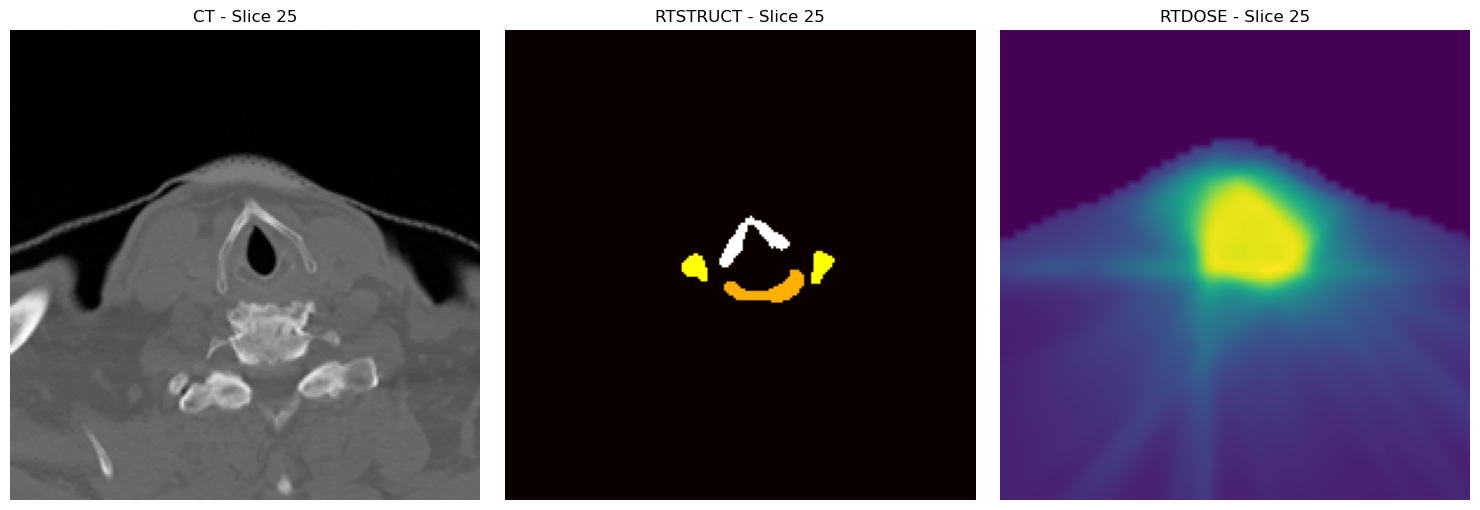

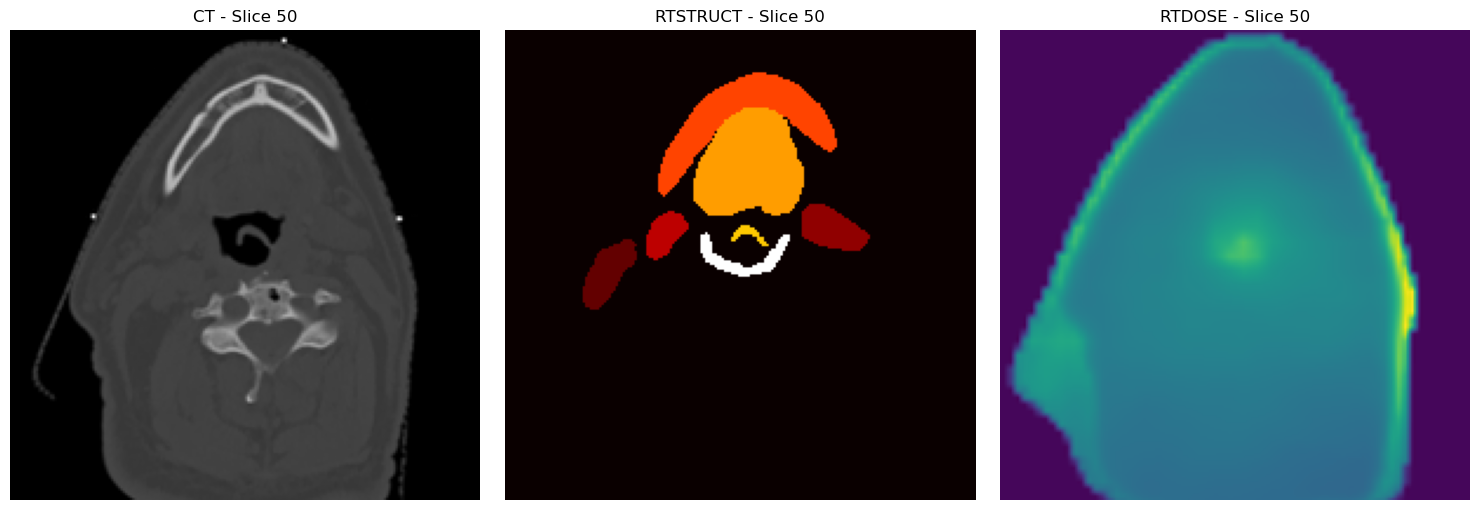

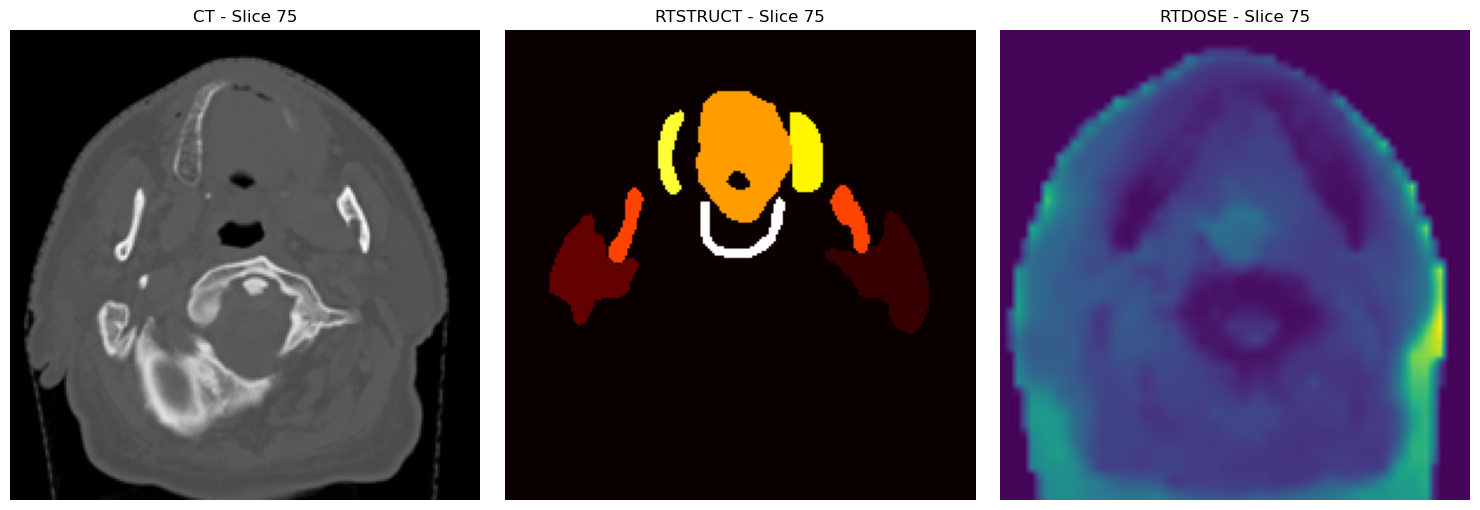

In [103]:
import matplotlib.pyplot as plt

# Select a few slices to visualize
slices = [preprocessed_CT.shape[0] // 4, preprocessed_CT.shape[0] // 2, 3 * preprocessed_CT.shape[0] // 4]

for slice_idx in slices:
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # Plot CT
    axes[0].imshow(preprocessed_CT[slice_idx], cmap='gray')
    axes[0].set_title(f'CT - Slice {slice_idx}')
    axes[0].axis('off')
    
    # Plot RTSTRUCT
    axes[1].imshow(preprocessed_RTSTRUCT[slice_idx], cmap='hot')
    axes[1].set_title(f'RTSTRUCT - Slice {slice_idx}')
    axes[1].axis('off')
    
    # Plot RTDOSE
    axes[2].imshow(preprocessed_RTDOSE[slice_idx], cmap='viridis')
    axes[2].set_title(f'RTDOSE - Slice {slice_idx}')
    axes[2].axis('off')
    
    plt.tight_layout()
    plt.show()